# AlongTrack Data - SWOT

> In this notebook, we will look at how one can do some simple regridding processes with the AlongTrack SWOT data available from the 2020a OSSE Data Challenge.

In [78]:
import autoroot
import typing as tp
from dataclasses import dataclass
import functools as ft
import numpy as np
import pandas as pd
import xarray as xr
from metpy.units import units
import pint_xarray
import xarray_dataclasses as xrdataclass
import matplotlib.pyplot as plt
import matplotlib.colors as colors
import matplotlib.ticker as ticker
import seaborn as sns

sns.reset_defaults()
sns.set_context(context="talk", font_scale=0.7)

%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Data

In [79]:
from ocn_tools._src.geoprocessing.validation import validate_latlon, validate_time, decode_cf_time, validate_ssh
from ocn_tools._src.preprocessing.alongtrack import alongtrack_ssh
from ocn_tools._src.geoprocessing.subset import where_slice
from ocn_tools._src.preprocessing.alongtrack import remove_swath_dimension


In [80]:
def preprocess_swot(da):
    
    print(da)
    
    # validate coordinates
    da = validate_latlon(da)
    da = validate_time(da)
    
    # validate variables
    da = da.rename({"ssh_model": "ssh"})
    da = validate_ssh(da)
    
    # slice time period
    # da = da.sel(time=slice("2012-10-22", "2012-12-03"))
    
    # remove SWATH dimension
    print(da)
    # # slice region
    # da = where_slice(da, "lon", -64.975, -55.007)
    # da = where_slice(da, "lat", 33.025, 42.9917)
    
    # reorganized
    da = da.sortby("time")
    
    # assign coordinates
    da = da.set_coords(["time", "lat", "lon"])
    
    return da #da[["ssh"]]


In [81]:
data_registry_dir = "/Volumes/EMANS_HDD/data/oceanbench-data-registry"

In [82]:
osse_dc20a_data_dir = f"{data_registry_dir}/osse_natl60/coord/swot"
!ls $osse_dc20a_data_dir

gf.nc     gf.nc.dvc


In [83]:
files_swot_dc20a = [
    f"{osse_dc20a_data_dir}/gf.nc",

    
]

In [84]:
%%time

ds_swot = xr.open_mfdataset(
    files_swot_dc20a, 
    preprocess=preprocess_swot,
    combine="nested",
    engine="netcdf4",
    concat_dim="time"
)

ds_swot = ds_swot.sortby("time").compute()

ds_swot

<xarray.Dataset>
Dimensions:      (time: 1676380, cycle: 1)
Coordinates:
  * time         (time) datetime64[ns] 2012-10-01T01:19:39.459757999 ... 2013...
Dimensions without coordinates: cycle
Data variables:
    lat          (time) float32 dask.array<chunksize=(1676380,), meta=np.ndarray>
    lon          (time) float32 dask.array<chunksize=(1676380,), meta=np.ndarray>
    model_index  (time) float32 dask.array<chunksize=(1676380,), meta=np.ndarray>
    nadir_err    (time) float32 dask.array<chunksize=(1676380,), meta=np.ndarray>
    ncycle       (time, cycle) float32 dask.array<chunksize=(1676380, 1), meta=np.ndarray>
    ssh_model    (time) float32 dask.array<chunksize=(1676380,), meta=np.ndarray>
    ssh_obs      (time) float32 dask.array<chunksize=(1676380,), meta=np.ndarray>
    x_al         (time) float32 dask.array<chunksize=(1676380,), meta=np.ndarray>
<xarray.Dataset>
Dimensions:      (time: 1676380, cycle: 1)
Coordinates:
  * time         (time) datetime64[ns] 2012-10-01T01:1

/Users/eman/miniconda3/envs/oceanbench_311/lib/python3.11/site-packages/xarray/core/concat.py:527: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))


CPU times: user 67.6 ms, sys: 53.7 ms, total: 121 ms
Wall time: 2.38 s


<xarray.Dataset>
Dimensions:      (time: 1676380, cycle: 1)
Coordinates:
    lat          (time) float32 62.17 62.14 62.11 62.08 ... 26.58 26.53 26.48
    lon          (time) float32 -65.84 -65.74 -65.64 ... -76.39 -76.36 -76.34
  * time         (time) datetime64[ns] 2012-10-01T01:19:39.459757999 ... 2013...
Dimensions without coordinates: cycle
Data variables:
    model_index  (time) float32 1.0 1.0 1.0 1.0 ... 8.72e+03 8.72e+03 8.72e+03
    nadir_err    (time) float32 -0.0143 0.0167 0.0071 ... 0.0077 0.0362 0.0149
    ncycle       (time, cycle) float32 9.921 9.921 9.921 ... 9.921 9.921 9.921
    ssh          (time) float32 -0.15 -0.1598 -0.1779 ... 0.7021 0.7036 0.7052
    ssh_obs      (time) float32 -0.1643 -0.1432 -0.1709 ... 0.7098 0.7397 0.7201
    x_al         (time) float32 1.882e+06 1.882e+06 ... 4.912e+06 4.912e+06

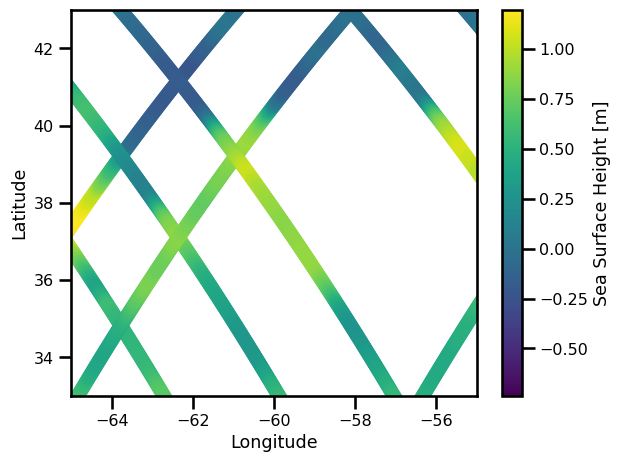

In [97]:
%matplotlib inline

fig, ax = plt.subplots()

sub_ds = ds_swot.sel(time=slice("2012-10-15","2012-10-20"))
variable = "ssh"
pts = ax.scatter(sub_ds.lon, sub_ds.lat, c=sub_ds[variable])
ax.set(
    xlabel="Longitude",
    ylabel="Latitude",
    xlim=[-65., -55.],
    ylim=[33., 43.]
)

plt.colorbar(pts, label="Sea Surface Height [m]")
plt.tight_layout()
plt.show()

### Gridding AlongTrack

In [86]:
data_registry_dir = "/Volumes/EMANS_HDD/data/oceanbench-data-registry"

In [87]:
osse_dc20a_data_dir = f"{data_registry_dir}/osse_natl60/grid/"
!ls $osse_dc20a_data_dir

gf_mod_ssh_daily.nc       gf_obs_nadir.nc.dvc       natl_mod_ssh_daily.nc.dvc
gf_mod_ssh_daily.nc.dvc   gf_obs_nadirswot.nc       natl_mod_sst.nc.dvc
gf_mod_sst.nc             gf_obs_nadirswot.nc.dvc   natl_obs_nadir.nc.dvc
gf_mod_sst.nc.dvc         gf_obs_swot.nc            natl_obs_nadirswot.nc.dvc
gf_obs_nadir.nc           gf_obs_swot.nc.dvc


In [51]:
files_swot_dc20a = [
    f"{osse_dc20a_data_dir}/gf_obs_swot.nc",

    
]

In [56]:
%%time

ds_swot = xr.open_mfdataset(
    files_swot_dc20a, 
    combine="nested",
    engine="netcdf4",
    concat_dim="time"
)

ds_swot = ds_swot.sortby("time").compute()

ds_swot

/Users/eman/miniconda3/envs/oceanbench_311/lib/python3.11/site-packages/xarray/core/concat.py:527: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  common_dims = tuple(pd.unique([d for v in vars for d in v.dims]))


CPU times: user 44.5 ms, sys: 191 ms, total: 236 ms
Wall time: 10.9 s


<xarray.Dataset>
Dimensions:      (time: 365, lat: 201, lon: 201)
Coordinates:
  * lon          (lon) float64 -65.0 -64.95 -64.9 -64.85 ... -55.1 -55.05 -55.0
  * lat          (lat) float64 33.0 33.05 33.1 33.15 ... 42.85 42.9 42.95 43.0
  * time         (time) datetime64[ns] 2012-10-01 2012-10-02 ... 2013-09-30
Data variables:
    mask         (time, lat, lon) float64 1.0 1.0 1.0 1.0 ... 1.0 1.0 1.0 1.0
    lag          (time, lat, lon) float64 nan nan nan nan ... nan nan nan nan
    flag         (time, lat, lon) float64 nan nan nan nan ... nan nan nan nan
    ssh_obs      (time, lat, lon) float64 nan nan nan nan ... nan nan nan nan
    ssh_mod      (time, lat, lon) float64 nan nan nan nan ... nan nan nan nan
    anomaly_obs  (time, lat, lon) float64 nan nan nan nan ... nan nan nan nan
    anomaly_mod  (time, lat, lon) float64 nan nan nan nan ... nan nan nan nan

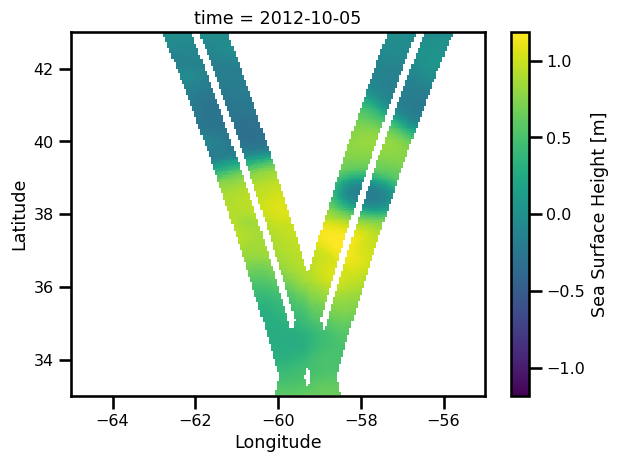

In [76]:
fig, ax = plt.subplots()

cbar_kwargs = {"label": "Sea Surface Height [m]"}
ds_swot.ssh_mod.isel(time=4).plot.pcolormesh(ax=ax, cmap="viridis",cbar_kwargs=cbar_kwargs)

ax.set(
    xlabel="Longitude",
    ylabel="Latitude",
    xlim=[-65., -55.],
    ylim=[33., 43.]
)


plt.tight_layout()
plt.show()